In [1]:
# import dependencies
import os
import numpy as np
import pandas as pd
import scanpy as sc
import loompy as lp
from MulticoreTSNE import MulticoreTSNE as TSNE
import matplotlib.pyplot as plt

In [2]:
wdir = r"Z:\selim_working_dir\2025_sato_anestacia_circadian_rhythm\r_pre_process\SCENIC_Output"
os.chdir( wdir )
dbs = r"\cisTarget_databases"
fname = r"sato_mouse_breast_cancer_scevan_decontX_QC_annotated_10_16_2025_subann.h5ad"
fname_metadata = r"metadata_circadian_mouse_breast_decontX_QC_10_15_2025_subann_matlab.xlsx"
fname_pyscenic_output = r"pyscenic_output.loom"

In [3]:
adata = sc.read_h5ad(fname)
df = pd.read_excel(fname_metadata)

In [4]:
# This is necessary for a direct comparison with adata.obs.index
df = df.set_index('CellID')
assert len(adata.obs) == len(df), "The number of cells in adata and df are different."
assert all(adata.obs.index == df.index), "Cell IDs in adata.obs and df are not identical or are not in the same order."
print("Assertion successful: Cell IDs in adata.obs and df match perfectly.")
# Select all columns from df *except* the index (which is 'CellID')
new_metadata_cols = df.columns

# Use the .loc indexer to assign the columns directly
# Since the indices already match (as asserted above), this is safe and fast.
adata.obs.loc[:, new_metadata_cols] = df

# Backup the raw count matrix...
adata.layers['counts'] = adata.X

Assertion successful: Cell IDs in adata.obs and df match perfectly.


In [5]:
ndim = 2           # Number of UMAP dimensions
n_neighbors = 15   # Number of neighbors for the graph
my_res = 1.0       # Clustering resolution (changed from 2.0 to 1.0 as requested)
algo_cluster = "leidenalg"

# --- Normalization and Log-Transform ---
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# --- Highly Variable Genes (HVG) ---
sc.pp.highly_variable_genes(adata, n_top_genes=5000, batch_key="sample_id_original")

# --- PCA and Neighbors ---
# 4. PCA (Step 7)
# Use 'highly_variable' genes determined during initial per-sample QC
npca = 50
use_hvg = adata.var['highly_variable'].sum() > 0
if adata.n_obs > 20000:
    print(f"PCA analysis in chunks of 10000 cells (n_comps={npca})...")
    sc.tl.pca(adata, n_comps=npca, use_highly_variable=use_hvg, chunked=True, chunk_size=10000, svd_solver="arpack")
else:
    print(f"PCA analysis (n_comps={npca})...")
    sc.tl.pca(adata, n_comps=npca, use_highly_variable=use_hvg, chunked=False, svd_solver="arpack")


# 5. Neighbors and UMAP (Step 8)
# This step uses the 50-component PCA result (final_adata.obsm['X_pca'])
print(f"Computing nearest neighbors (k={n_neighbors}) and UMAP (n_dims={ndim})...")
sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=npca)
sc.tl.umap(adata, n_components=ndim)

# 6. Global Leiden Clustering (Replacing Batch-Aware Clustering)
# This runs Leiden once on the entire graph structure computed from the 50 PCs.
cluster_key = f'leiden_res{my_res}' # Renamed key to reflect global clustering
print(f"\nComputing **Global** Leiden clusters (res={my_res}, flavor={algo_cluster}) on all {adata.n_obs} cells...")

sc.tl.leiden(
    adata,
    flavor=algo_cluster,
    n_iterations=2, # Use n_iterations=2 as in the previous code
    resolution=my_res,
    key_added=cluster_key
)

print(f"Global Leiden clustering complete. Results in adata.obs['{cluster_key}']")

PCA analysis in chunks of 10000 cells (n_comps=50)...


c:\Local_install\miniconda3\envs\pyscenic\Lib\site-packages\scanpy\preprocessing\_pca.py:374: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


Computing nearest neighbors (k=15) and UMAP (n_dims=2)...

Computing **Global** Leiden clusters (res=1.0, flavor=leidenalg) on all 223977 cells...


C:\Users\ssromerogon\AppData\Local\Temp\ipykernel_28036\1391541174.py:37: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Global Leiden clustering complete. Results in adata.obs['leiden_res1.0']



Plotting UMAP colored by leiden_res1.0 and saving...


[<Axes: title={'center': 'leiden_res1.0'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'broad_cell_types'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'sub_cell_types'}, xlabel='UMAP1', ylabel='UMAP2'>]

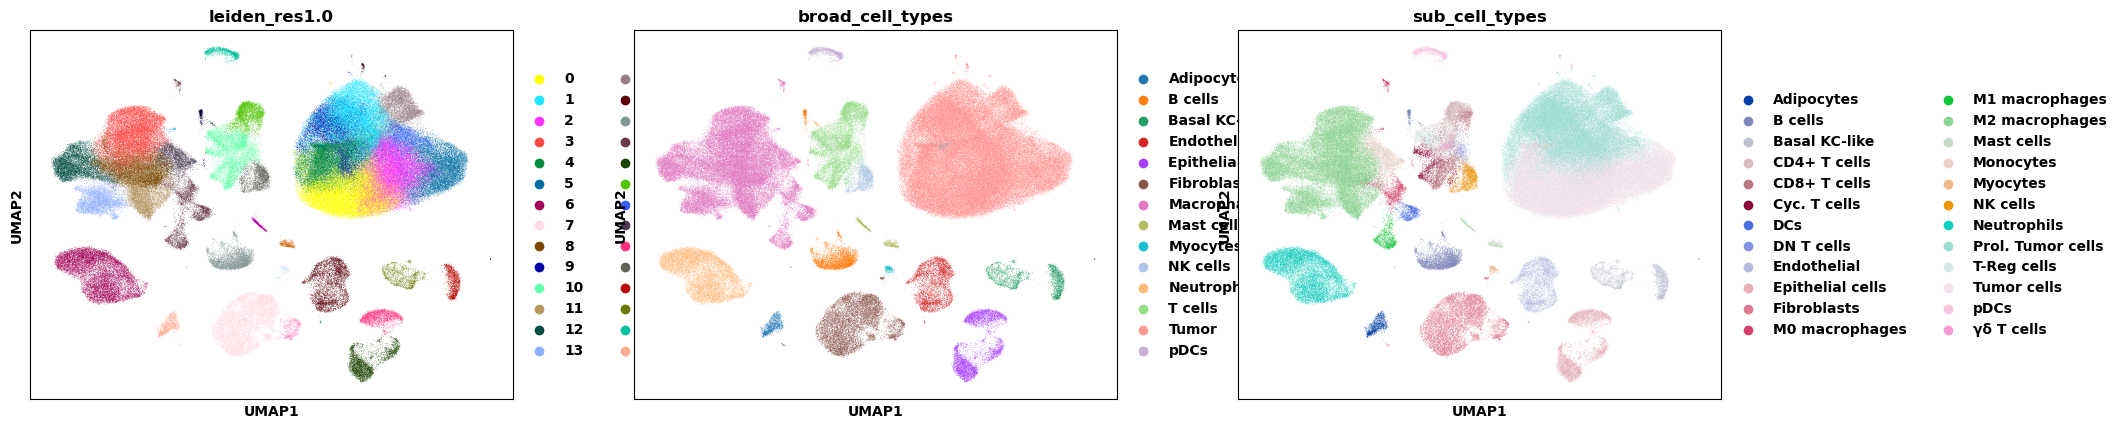

In [6]:
# 7. Plot and Save UMAP
print(f"\nPlotting UMAP colored by {cluster_key} and saving...")
sc.pl.umap(adata, color=[cluster_key,"broad_cell_types","sub_cell_types"], show=False)

In [5]:
from scipy.sparse import issparse
def save_loom_file( adata, fname, layer: str = None):
    """
    Saves an anndata object to a loom file.
    
    WARNING: The loom file will be saved in a non-standard (Genes x Cells) 
    orientation due to the required matrix transposition.
    """
    # Select the matrix to be saved (X or a layer)
    if layer is None:
        mat = adata.X
    else:
        # Correct access to the layer matrix
        if layer not in adata.layers:
            raise ValueError(f"Layer '{layer}' not found in adata.layers.")
        mat = adata.layers[layer]

    # --- Row Attributes (Genes) ---
    row_attrs = { 
        "Gene": np.array(adata.var.index) ,
    }

    if issparse(mat): # Use the imported function to check the type
        mat = mat.toarray()

    # --- Column Attributes (Cells) ---
    # NOTE: Attribute calculation must be done on the standard (Cells x Genes) matrix.
    # The result (N_cells length) is then assigned to col_attrs.
    # Since the final loom matrix will be transposed (Genes x Cells), 
    # the col_attrs will be incorrectly associated with the gene axis, 
    # but the calculation itself is correct for the cell metrics.
    
    # Calculate cell metrics on the selected matrix 'mat'
    # Use axis=1 to sum across genes for each cell
    n_gene_counts = np.array((mat > 0).sum(axis=1)).flatten()
    n_umi_counts = np.array(mat.sum(axis=1)).flatten()

    col_attrs = { 
        "CellID": np.array(adata.obs.index),
        "nGene": n_gene_counts,
        "nUMI": n_umi_counts,
    }

    # CRITICAL WARNING: Retaining the non-standard transposition as requested.
    # The matrix passed to lp.create is (Genes x Cells).
    lp.create(fname, mat.transpose(), row_attrs, col_attrs)

    return

In [6]:
new_order = ['Early', 'Intermediate', 'Advanced']
adata.obs['tumor_stage'] = adata.obs['tumor_stage'].cat.reorder_categories(
    new_order, ordered=True)
ordered_categories = adata.obs['tumor_stage'].cat.categories
cancer_stages = ordered_categories.tolist()
print(cancer_stages)

cell_levels = [
    "Adipocytes", "B cells", "Basal KC-like", "Endothelial",
    "Epithelial cells", "Fibroblasts", "Macrophages", "Mast cells",
    "NK cells", "Neutrophils", "T cells", "Tumor", "pDCs", "Myocytes"
]
adata.obs['broad_cell_types'] = adata.obs['broad_cell_types'].cat.reorder_categories(
    cell_levels, ordered=True)
ordered_categories = adata.obs['broad_cell_types'].cat.categories
cell_types = ordered_categories.tolist()
print(cell_types)

['Early', 'Intermediate', 'Advanced']
['Adipocytes', 'B cells', 'Basal KC-like', 'Endothelial', 'Epithelial cells', 'Fibroblasts', 'Macrophages', 'Mast cells', 'NK cells', 'Neutrophils', 'T cells', 'Tumor', 'pDCs', 'Myocytes']


In [ ]:
import os
import glob
import numpy as np # Ensure numpy is imported for the filtering section

# --- Configuration (FIXED PATHS) ---
dbs_dir = "cisTarget_databases" 
f_tfs = os.path.join(dbs_dir, 'allTFs_mm.txt')
nprocs = 4

# Use os.path.join for robustness
f_db_glob = os.path.join(dbs_dir, "*.feather")
f_db_names = ' '.join( glob.glob(f_db_glob) )
f_motif_path = os.path.join(dbs_dir, "motifs-v9-nr.mgi-m0.001-o0.0.tbl")
# ------------------------------------

# --- Function to check file existence and size (Helper) ---
def needs_computation(filepath):
    """
    Checks if a file exists and has a size > 0 bytes.
    Returns True if computation is needed (file missing or 0 bytes), False otherwise.
    """
    if not os.path.exists(filepath):
        print(f"File '{os.path.basename(filepath)}' not found. Computing.")
        return True
    
    # os.path.getsize returns the size in bytes (0 bytes = 0 kb)
    if os.path.getsize(filepath) == 0: 
        print(f"File '{os.path.basename(filepath)}' is 0 bytes. Re-computing.")
        return True
    
    print(f"File '{os.path.basename(filepath)}' exists and has size > 0 bytes. Skipping computation.")
    return False
# -----------------------------------------------------------

for icells_type in cell_types:
    icells = adata.obs['broad_cell_types'] == icells_type
    icells_type_sanitized = icells_type.replace(" ", "_")
    # CRITICAL CHECK: Add check for zero total cells for the broad type
    if sum(icells) == 0:
        print(f"Not enough cells...")
        continue
    
    print(f"\n--- Cell Type: {icells_type} (Total Cells: {sum(icells)}) ---")
    
    for istage in cancer_stages:
        ican_stage = adata.obs['tumor_stage'] == istage
        
        idx = ican_stage & icells
        num_cells = sum(idx) # Get current cell count
        
        # Check if the subset has cells before proceeding
        if num_cells == 0:
            print(f"  Stage '{istage}': 0 cells. Skipping.")
            continue
            
        sub_adata = adata[idx, :].copy()
        
        # --- GENE FILTERING ---
        min_cells_percent = 0.10
        min_cells = int(num_cells * min_cells_percent) 

        mat_to_filter = sub_adata.layers['counts'] if 'counts' in sub_adata.layers else sub_adata.X
        # Note: Added .todense() to ensure sum works correctly if mat_to_filter is sparse
        gene_counts = (mat_to_filter > 0).sum(axis=0).A.flatten() if hasattr(mat_to_filter, 'A') else (mat_to_filter > 0).sum(axis=0).flatten()
        genes_to_keep = gene_counts >= min_cells
        
        # Filter the adata object
        sub_adata = sub_adata[:, genes_to_keep].copy()
        n_genes = sub_adata.shape[1]
        
        print(f"  Stage '{istage}': {num_cells} cells and {n_genes} genes (Filtered)")

        # --- PYSCENIC STEPS ---
        fname_loom = f"{icells_type_sanitized}_{istage}.loom"
        fname_adj = f"{icells_type_sanitized}_{istage}_adj.csv"
        fname_reg = f"{icells_type_sanitized}_{istage}_regulons.csv"

        # 1. Save Loom File
        # It's usually safe to overwrite the loom file, but you could add a check here too.
        # For this example, we assume saving the loom is fast and necessary setup.
        save_loom_file( sub_adata, fname_loom, layer='counts')

        # 2. PySCENIC GRN (Checkpoint)
        if needs_computation(fname_adj):
            print("  Running GRN...")
            !pyscenic grn {fname_loom} {f_tfs} -o {fname_adj} --num_workers {nprocs}
            
        # 3. PySCENIC CTX (Checkpoint)
        if needs_computation(fname_reg):
            print("  Running CTX...")
            !pyscenic ctx {fname_adj} {f_db_names} --annotations_fname {f_motif_path} \
            --expression_mtx_fname {fname_loom} --output {fname_reg} --mask_dropouts --num_workers {nprocs}


--- Cell Type: Adipocytes (Total Cells: 1360) ---
  Stage 'Early': 839 cells and 5980 genes (Filtered)
File 'Adipocytes_Early_adj.csv' exists and has size > 0 bytes. Skipping computation.
File 'Adipocytes_Early_regulons.csv' exists and has size > 0 bytes. Skipping computation.
  Stage 'Intermediate': 346 cells and 7003 genes (Filtered)
File 'Adipocytes_Intermediate_adj.csv' exists and has size > 0 bytes. Skipping computation.
File 'Adipocytes_Intermediate_regulons.csv' exists and has size > 0 bytes. Skipping computation.
  Stage 'Advanced': 175 cells and 7166 genes (Filtered)
File 'Adipocytes_Advanced_adj.csv' exists and has size > 0 bytes. Skipping computation.
File 'Adipocytes_Advanced_regulons.csv' exists and has size > 0 bytes. Skipping computation.

--- Cell Type: B cells (Total Cells: 4698) ---
  Stage 'Early': 53 cells and 4498 genes (Filtered)
File 'B_cells_Early_adj.csv' exists and has size > 0 bytes. Skipping computation.
File 'B_cells_Early_regulons.csv' exists and has size

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import numpy as np

# --- 1. Configuration ---
BASE_DIR = r'Z:\selim_working_dir\2025_sato_anestacia_circadian_rhythm\r_pre_process\SCENIC_Output\hprc_output'
NES_THRESHOLD = 3.0
Q_VALUE_THRESHOLD = 0.05 

FILE_PATTERN = os.path.join(BASE_DIR, '*_regulons.csv')
FILE_PATHS = glob.glob(FILE_PATTERN)

if not FILE_PATHS:
    print("⚠️ WARNING: Could not find any files matching the pattern: '*_regulons.csv'")
    print("Please ensure the directory path is correct and the files exist.")
    FILE_PATHS = [
        os.path.join(BASE_DIR, 'B_cells_Early_regulons.csv'),
        os.path.join(BASE_DIR, 'Tumor_Early_regulons.csv')
    ]

classic_circ_tfs = [
    "arntl", "bhlh", "clock", "cry", "dbp", "tef", "hlf", "raf", "erk",
    "mek", "ras", "mtor", "map", "ral", "akt", "hif", "kras", "myc",
    "nfkb", "per", "wnt", "nr1d", "rev", "pik", "ror"
]
 
# --- 2. Data Loading and Cleaning Function (Robust) ---
def load_and_clean_pyscenic_df(path):
    """Loads, cleans, and processes the pySCENIC motif output."""
    try:
        # 2.1 Process TF and MotifID columns (df1)
        df1 = pd.read_csv(path, header=2, usecols=[0, 1])
        df1 = df1.rename(columns={'MotifID': 'Enrichment MotifID'})
        
        # 2.2 Process Enrichment metric columns (df2)
        df_temp = pd.read_csv(path, header=None, usecols=range(2, 10))
        metric_names = df_temp.iloc[1].values
        new_cols = [f"Enrichment {m}" for m in metric_names]
        
        # Data starts at the third physical row (index 2), skipping both header rows
        df2 = df_temp.iloc[2:].copy() 
        df2.columns = new_cols
        df2 = df2.reset_index(drop=True)
        
        # 2.3 Concatenate df1 and df2
        df_final = pd.concat([df1.reset_index(drop=True), df2.reset_index(drop=True)], axis=1)
        df_final = df_final.dropna(how='all')
        
        # Convert NES and Q-value columns to numeric
        df_final['Enrichment NES'] = pd.to_numeric(df_final['Enrichment NES'], errors='coerce')
        df_final['Enrichment MotifSimilarityQvalue'] = pd.to_numeric(df_final['Enrichment MotifSimilarityQvalue'], errors='coerce')
        
        return df_final
    except Exception as e:
        print(f"Error processing file {path}: {e}. Skipping.")
        return None

# Load the data
try:
    pass 
except Exception as e:
    print(f"❌ An error occurred during file list retrieval: {e}")
    exit()

# --- 3. Loop through files and build the matrix ---
nes_series_list = []
print(f"Starting analysis on {len(FILE_PATHS)} potential file paths...")

for full_path in FILE_PATHS:
    file_name = os.path.basename(full_path)
    print(f"\nProcessing {file_name}...")
    
    # The cell type name is everything before '_regulons.csv'
    if '_regulons.csv' in file_name:
        cell_type = file_name.split('_regulons.csv')[0]
    else:
        cell_type = file_name.split('.')[0]
    
    df_full = load_and_clean_pyscenic_df(full_path)
    
    if df_full is None:
        continue

    df_full['TF_lower'] = df_full['TF'].str.lower()
    
    # 3.1 Filter for ALL significant results
    df_significant = df_full[
        (df_full['Enrichment NES'] >= NES_THRESHOLD) & 
        (df_full['Enrichment MotifSimilarityQvalue'] < Q_VALUE_THRESHOLD)
    ].copy()
    
    # 3.2 Filter for Circadian TFs that are present and significant in this sample
    df_top_motifs_circadian = df_significant[
        df_significant['TF_lower'].isin(classic_circ_tfs)
    ].copy()
    
    if df_top_motifs_circadian.empty:
        print(f"No significant circadian TFs found in {file_name}.")
        continue
        
    # 3.3 Select the single BEST motif (highest NES) to represent each TF
    idx = df_top_motifs_circadian.groupby('TF')['Enrichment NES'].idxmax()
    df_top_motifs = df_top_motifs_circadian.loc[idx]
    
    # 3.4 Convert the result to a Series for matrix building
    nes_series = df_top_motifs.set_index('TF')['Enrichment NES'].rename(cell_type)
    nes_series_list.append(nes_series)


Starting analysis on 42 potential file paths...

Processing Adipocytes_Advanced_regulons.csv...

Processing Adipocytes_Early_regulons.csv...

Processing Adipocytes_Intermediate_regulons.csv...

Processing Basal_KC-like_Advanced_regulons.csv...

Processing Basal_KC-like_Early_regulons.csv...

Processing Basal_KC-like_Intermediate_regulons.csv...

Processing B_cells_Advanced_regulons.csv...

Processing B_cells_Early_regulons.csv...

Processing B_cells_Intermediate_regulons.csv...

Processing Endothelial_Advanced_regulons.csv...

Processing Endothelial_Early_regulons.csv...

Processing Endothelial_Intermediate_regulons.csv...

Processing Epithelial_cells_Advanced_regulons.csv...

Processing Epithelial_cells_Early_regulons.csv...

Processing Epithelial_cells_Intermediate_regulons.csv...

Processing Fibroblasts_Advanced_regulons.csv...

Processing Fibroblasts_Early_regulons.csv...

Processing Fibroblasts_Intermediate_regulons.csv...

Processing Macrophages_Advanced_regulons.csv...

Processi


--- Final NES Matrix for Heatmap ---
Matrix Shape: (6, 42) (TFs x Cell Types)

📈 Generating transposed heatmap (Cell Types on Y, TFs on X)...


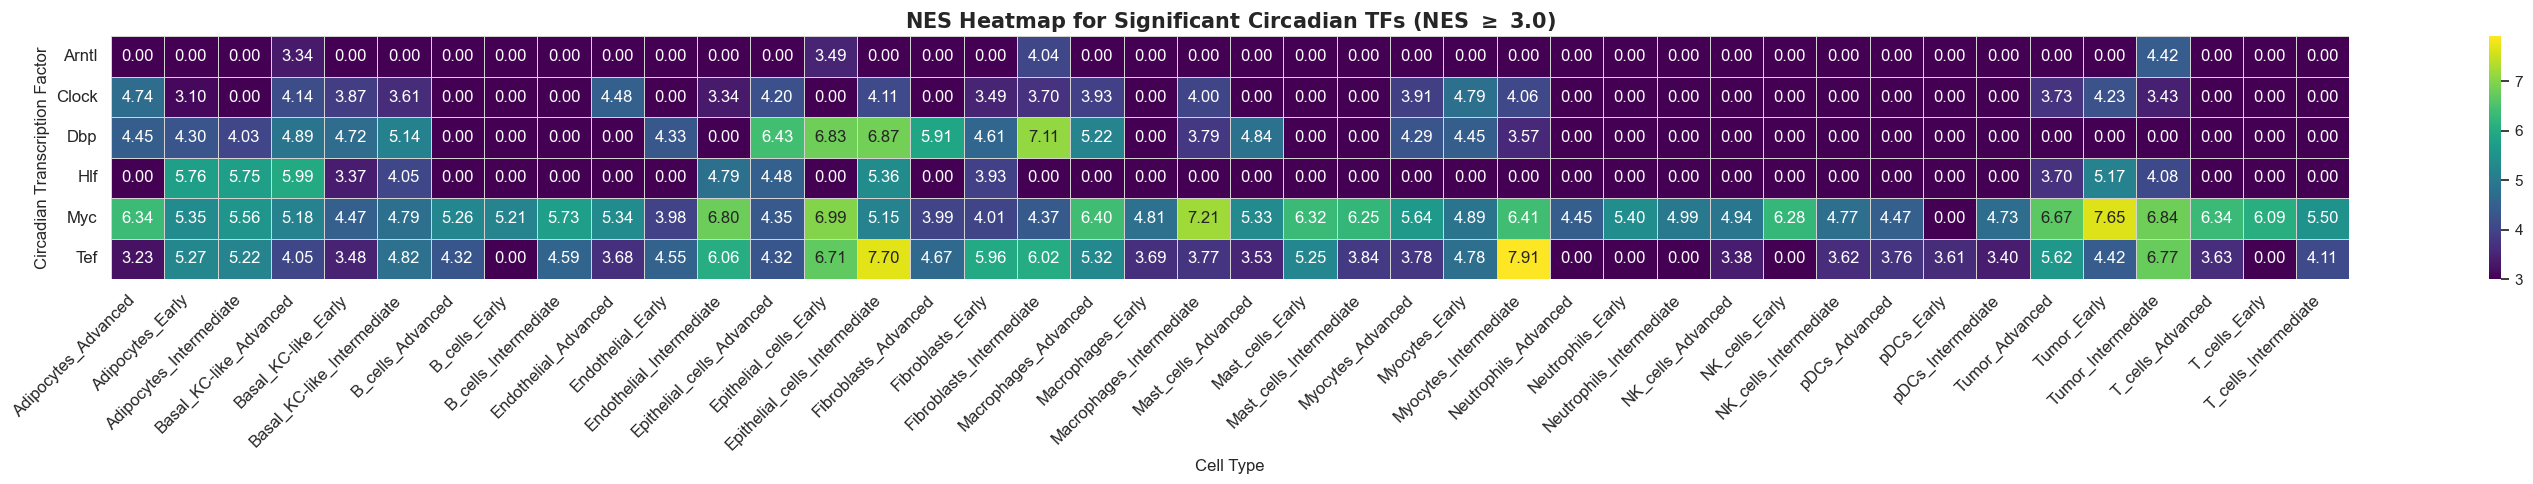


✨ Transposed Heatmap generation complete and saved as: Circadian_TF_NES_Heatmap_Sorted.svg


In [ ]:
# --- 4. Build the final NES matrix (Heatmap Data) ---

if not nes_series_list:
    print("\nFinal matrix construction failed: No significant circadian TFs were found across any file.")
    exit()

# Concatenate all series into one DataFrame (TFs as rows, Cell Types as columns)
nes_matrix = pd.concat(nes_series_list, axis=1)

# Fill NaNs (where a TF was NOT significant in a cell type) with 0
nes_matrix = nes_matrix.fillna(0) 

# Sort TFs by max NES across all cell types for better visualization
nes_matrix['Max_NES'] = nes_matrix.max(axis=1)
nes_matrix = nes_matrix.sort_values(by='Max_NES', ascending=False).drop(columns=['Max_NES'])
print("\n--- Final NES Matrix for Heatmap ---")
print(f"Matrix Shape: {nes_matrix.shape} (TFs x Cell Types)")

# =======================================================
# --- CUSTOM SORTING LOGIC FOR Y-AXIS (Cell Type) ---
# =======================================================
# Transpose the matrix first so the Cell Types are the index (rows)
#nes_matrix_transposed = nes_matrix.T 
nes_matrix_transposed = nes_matrix

# 4.1 Define the desired stage order (MUST match suffixes in file names)
# NOTE: Using a robust order for the common stages observed in your files
stage_order = {'Early': 0, 'Intermediate': 1, 'Advanced': 2} 

# 4.2 Create sorting keys from the index (Cell Type) names
def get_sort_keys(cell_type_name):
    parts = cell_type_name.split('_')
    
    # Find the stage tag at the end (e.g., 'Early', 'Intermediate', 'Advanced')
    stage_tag = None
    if parts[-1] in stage_order:
        stage_tag = parts[-1]
        base_name = '_'.join(parts[:-1]) # e.g., 'B_cells'
    else:
        # For base cell types without a stage tag (e.g., 'B_cells' or 'Tumor')
        base_name = cell_type_name
    
    # Assign the base name (alphabetical sort) and stage order
    # Default stage order is 99 (or 0 if you assume base cell is 'Early')
    order_value = stage_order.get(stage_tag, stage_order.get('Early', 99))
    return (base_name.lower(), order_value)

# 4.3 Apply the custom sort keys to the index
nes_matrix_transposed = nes_matrix_transposed.sort_index(key=lambda index: [get_sort_keys(name) for name in index])

# =======================================================
# --- 5. Generate the Heatmap Plot (Transposed) ---
# =======================================================

print("\n📈 Generating transposed heatmap (Cell Types on Y, TFs on X)...")

# Create figure
plt.figure(figsize=(max(8, nes_matrix_transposed.shape[1] * 0.7), max(5, nes_matrix_transposed.shape[0] * 0.4))) 

sns.set_theme(style="whitegrid")

# Create the heatmap and assign to 'ax'
ax = sns.heatmap(
    nes_matrix_transposed, 
    cmap="viridis", 
    annot=True, 
    fmt=".2f", 
    linewidths=.5, 
    linecolor='lightgray',
    vmin=NES_THRESHOLD, 
    vmax=nes_matrix_transposed.values.max()
)

# --- Apply desired font size for tick labels ---
ax.tick_params(axis='x', labelsize=12) 
ax.tick_params(axis='y', labelsize=12) 

# Plot formatting
plt.title(f'NES Heatmap for Significant Circadian TFs (NES $\geq$ {NES_THRESHOLD})', fontsize=15)
plt.ylabel('Circadian Transcription Factor', fontsize=12)
plt.xlabel('Cell Type', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save as SVG
output_filename = 'Circadian_TF_NES_Heatmap_Sorted.svg'
plt.savefig(output_filename, bbox_inches='tight')

plt.show()

print(f"\nTransposed Heatmap generation complete and saved as: {output_filename}")

In [ ]:
import pandas as pd
import os
import glob

# --- 1. Configuration ---
# Define the path to the directory containing your files
BASE_DIR = r'Z:\selim_working_dir\2025_sato_anestacia_circadian_rhythm\r_pre_process\SCENIC_Output\hprc_output'

# Create a pattern to find all regulon files
FILE_PATTERN = os.path.join(BASE_DIR, '*_regulons.csv')
FILE_PATHS = glob.glob(FILE_PATTERN)

if not FILE_PATHS:
    print(f"WARNING: No files found matching the pattern: {FILE_PATTERN}")
    # You can add fallback paths here if needed, but it's better to ensure the path is correct.

# --- 2. Your Custom Data Loading and Cleaning Function ---
# This function is perfect for handling the complex headers of your specific files.
def load_and_clean_pyscenic_df(path):
    """Loads, cleans, and processes a pySCENIC motif output file."""
    try:
        # 2.1 Process TF and MotifID columns (df1)
        df1 = pd.read_csv(path, header=2, usecols=[0, 1])
        df1 = df1.rename(columns={'MotifID': 'Enrichment MotifID'})
        
        # 2.2 Process Enrichment metric columns (df2)
        df_temp = pd.read_csv(path, header=None, usecols=range(2, 10))
        metric_names = df_temp.iloc[1].values
        new_cols = [f"Enrichment {m}" for m in metric_names]
        
        # Data starts at the third physical row (index 2)
        df2 = df_temp.iloc[2:].copy() 
        df2.columns = new_cols
        df2 = df2.reset_index(drop=True)
        
        # 2.3 Concatenate df1 and df2
        df_final = pd.concat([df1.reset_index(drop=True), df2.reset_index(drop=True)], axis=1)
        df_final = df_final.dropna(how='all')
        
        # Convert NES and Q-value columns to numeric
        df_final['Enrichment NES'] = pd.to_numeric(df_final['Enrichment NES'], errors='coerce')
        df_final['Enrichment MotifSimilarityQvalue'] = pd.to_numeric(df_final['Enrichment MotifSimilarityQvalue'], errors='coerce')
        
        return df_final
    except Exception as e:
        print(f"Error processing file {os.path.basename(path)}: {e}. Skipping.")
        return None

# --- 3. Main Loop to Load All Files into a Dictionary ---
all_dataframes = {}
print(f"Found {len(FILE_PATHS)} files to process...\n")

for path in FILE_PATHS:
    filename = os.path.basename(path)
    
    # Generate a clean key for the dictionary (e.g., 'Fibroblasts_Advanced')
    key_name = filename.replace('_regulons.csv', '')
    print(f"Processing: {filename}...")
    
    # Load and clean the dataframe using your function
    cleaned_df = load_and_clean_pyscenic_df(path)
    
    # If the dataframe was loaded successfully, add it to our dictionary
    if cleaned_df is not None:
        all_dataframes[key_name] = cleaned_df
        print(f"  -> Successfully loaded and cleaned. Stored as '{key_name}'.")

# --- POST-PROCESSING STARTS HERE ---

print("\n" + "="*50)
print("LOADING AND CLEANING COMPLETE")
print("="*50)
print(f"Successfully loaded {len(all_dataframes)} dataframes.")
print("You can access them using the following keys:")
print(list(all_dataframes.keys()))

# Example: Access one of the dataframes and show its info
if 'Fibroblasts_Advanced' in all_dataframes:
    print("\n--- Example: Showing info for 'Fibroblasts_Advanced' DataFrame ---")
    fib_adv_df = all_dataframes['Fibroblasts_Advanced']
    print(fib_adv_df.info())
    print("\n--- Head of 'Fibroblasts_Advanced' DataFrame ---")
    print(fib_adv_df.head())

In [ ]:
# ==============================================================================
# PART 2: LOAD CIRCADIAN ANALYSIS FILES (Corrected Logic with Key Normalization)
# ==============================================================================
# --- 4. Configuration for Circadian files (Corrected) ---
# This is the single parent directory that contains ALL the 'stage_*_pop' folders.
BASE_DIR_CIRCADIAN = r'Z:\selim_working_dir\2025_sato_anestacia_circadian_rhythm\r_pre_process\circadian_analysis_ftetst_plus_corr_test'
# List of the sub-folders to search inside the base directory
STAGE_DIRS = ['stage_Intermediate_pop', 'stage_Advanced_pop', 'stage_Earl_pop']
#STAGE_DIRS = ['stage_Intermediate_sub_pop', 'stage_Advanced_sub_pop', 'stage_Earl_sub_pop']

FILE_SUFFIX = '_period_24__macro_circadian_analysis.csv'

# --- 5. Main Loop to Load Circadian Files ---
circadian_dataframes = {}
print(f"\n\nNow searching for Circadian Analysis files...")
# Loop through the list of stage sub-folders
for stage_folder in STAGE_DIRS:
    
    # Construct the full, correct path to the stage folder
    current_dir_path = os.path.join(BASE_DIR_CIRCADIAN, stage_folder)
    
    # Check if this correct directory path actually exists
    if not os.path.isdir(current_dir_path):
        print(f"\n⚠️ Directory not found, skipping: {current_dir_path}")
        continue
        
    print(f"\nSearching in directory: {current_dir_path}")
    
    # Find all files matching the specified pattern within this stage directory
    file_pattern = os.path.join(current_dir_path, f"*{FILE_SUFFIX}")
    circadian_file_paths = glob.glob(file_pattern)
    
    if not circadian_file_paths:
        print("  -> No matching files found in this directory.")
        continue
        
    # Loop through each found file
    for path in circadian_file_paths:
        filename = os.path.basename(path)
        
        # Extract the cell type from the filename
        celltype = filename.replace(FILE_SUFFIX, '')
        
        # *** NEW: NORMALIZE THE CELLTYPE NAME ***
        # Replace any spaces with underscores to ensure consistency
        celltype_normalized = celltype.replace(' ', '_')
        
        # Construct the desired key name using the normalized celltype
        key_name = f"{stage_folder}_{celltype_normalized}"
        
        print(f"  -> Reading file: {filename}")
        try:
            # Read the file as a standard CSV
            df = pd.read_csv(path)
            circadian_dataframes[key_name] = df
            print(f"     ... Stored in dictionary with key: '{key_name}'")
        except Exception as e:
            print(f"     ... ❌ ERROR: Could not read file. {e}")

# --- 6. Final Summary ---
print("\n" + "="*50)
print("✅ CIRCADIAN FILE LOADING COMPLETE")
print("="*50)
print(f"Successfully loaded {len(circadian_dataframes)} circadian dataframes.")
print("You can access them using the following keys:")
print(list(circadian_dataframes.keys()))

# Example: Access one of the newly loaded circadian dataframes
# Let's check for the normalized key 'stage_Advanced_pop_T_cells'
if 'stage_Advanced_pop_T_cells' in circadian_dataframes:
    print("\n--- Example: Head of 'stage_Advanced_pop_T_cells' DataFrame ---")
    print(circadian_dataframes['stage_Advanced_pop_T_cells'].head())



Now searching for Circadian Analysis files...

Searching in directory: Z:\selim_working_dir\2025_sato_anestacia_circadian_rhythm\r_pre_process\circadian_analysis_ftetst_plus_corr_test\stage_Intermediate_sub_pop
  -> Reading file: Adipocytes_period_24__macro_circadian_analysis.csv
     ... Stored in dictionary with key: 'stage_Intermediate_sub_pop_Adipocytes'
  -> Reading file: B cells_period_24__macro_circadian_analysis.csv
     ... Stored in dictionary with key: 'stage_Intermediate_sub_pop_B_cells'
  -> Reading file: CD4+ T cells_period_24__macro_circadian_analysis.csv
     ... Stored in dictionary with key: 'stage_Intermediate_sub_pop_CD4+_T_cells'
  -> Reading file: CD8+ T cells_period_24__macro_circadian_analysis.csv
     ... Stored in dictionary with key: 'stage_Intermediate_sub_pop_CD8+_T_cells'
  -> Reading file: Cyc. T cells_period_24__macro_circadian_analysis.csv
     ... Stored in dictionary with key: 'stage_Intermediate_sub_pop_Cyc._T_cells'
  -> Reading file: Dendritic ce

In [38]:
print(list(circadian_dataframes.keys()))

['stage_Intermediate_sub_pop_Adipocytes', 'stage_Intermediate_sub_pop_B_cells', 'stage_Intermediate_sub_pop_CD4+_T_cells', 'stage_Intermediate_sub_pop_CD8+_T_cells', 'stage_Intermediate_sub_pop_Cyc._T_cells', 'stage_Intermediate_sub_pop_Dendritic_cells', 'stage_Intermediate_sub_pop_DN_T_cells', 'stage_Intermediate_sub_pop_Endothelial', 'stage_Intermediate_sub_pop_Epithelial_cells', 'stage_Intermediate_sub_pop_Fibroblasts', 'stage_Intermediate_sub_pop_Keratinocytes', 'stage_Intermediate_sub_pop_M0_macrophages', 'stage_Intermediate_sub_pop_M1_macrophages', 'stage_Intermediate_sub_pop_M2_macrophages', 'stage_Intermediate_sub_pop_Mast_cells', 'stage_Intermediate_sub_pop_Monocytes', 'stage_Intermediate_sub_pop_Myocytes', 'stage_Intermediate_sub_pop_Neutrophils', 'stage_Intermediate_sub_pop_NK_cells', 'stage_Intermediate_sub_pop_Non-proliferation_tumor_cells', 'stage_Intermediate_sub_pop_Plascytoid_dendritic_cells', 'stage_Intermediate_sub_pop_Proliferation_tumor_cells', 'stage_Intermediate_

In [39]:
# ==============================================================================
# PART 3: INTEGRATED ANALYSIS OF REGULONS AND CIRCADIAN DATA (with Summary Report)
# ==============================================================================

print("\n\n" + "="*50)
print("✅ STARTING INTEGRATED ANALYSIS")
print("="*50)

# --- Configuration ---
CIRCADIAN_PVAL_THRESHOLD = 0.05
CIRCADIAN_PCORR_THRESHOLD = 0.05
TOP_N_TFS = 10

# --- Main Analysis Loop ---
top_tfs_results = []
summary_stats = []  # <<< NEW: Initialize list to store summary stats

# Loop through the SCENIC regulon dataframes
for key, regulon_df in all_dataframes.items():
    
    # 1. Parse CellType and Stage
    key_parts = key.split('_')
    stage = key_parts[-1]
    cell_type = '_'.join(key_parts[:-1])
    print(f"\n--- Processing: CellType='{cell_type}', Stage='{stage}' ---")
    
    # Initialize stats for this iteration
    total_regulon_tfs = len(regulon_df['TF'].unique())
    num_circadian_genes = 0
    num_overlapping_tfs = 0
    
    # 2. Find the corresponding circadian dataframe
    circadian_key = f"stage_{stage}_pop_{cell_type}"
    if circadian_key not in circadian_dataframes:
        print(f"  -> No matching circadian data found for key: {circadian_key}. Skipping.")
        # <<< NEW: Store stats before skipping
        summary_stats.append({
            'CellType': cell_type,
            'Stage': stage,
            'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': 'N/A',
            'Overlapping TFs': 'N/A',
            'Top TFs Found': 0
        })
        continue
    
    circadian_df = circadian_dataframes[circadian_key]
    
    # 3. Get the list of "circadian-significant" genes
    circadian_significant_genes = circadian_df[
        (circadian_df['pvalue'] < CIRCADIAN_PVAL_THRESHOLD) & 
        (circadian_df['pvalue_corr'] < CIRCADIAN_PCORR_THRESHOLD)
    ]
    
    # <<< NEW: Update stats
    num_circadian_genes = len(circadian_significant_genes)
    
    if circadian_significant_genes.empty:
        print(f"  -> No circadian-significant genes found...")
        # <<< NEW: Store stats before skipping
        summary_stats.append({
            'CellType': cell_type,
            'Stage': stage,
            'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': num_circadian_genes,
            'Overlapping TFs': 0,
            'Top TFs Found': 0
        })
        continue
        
    circadian_gene_set = set(g.lower() for g in circadian_significant_genes['Genes'])
    print(f"  -> Found {len(circadian_gene_set)} circadian-significant genes.")
    
    # 4. Filter the regulon dataframe
    regulon_df_cleaned = regulon_df.dropna(subset=['TF', 'Enrichment NES']).copy()
    
    # Get the unique TFs from the regulon file for counting
    unique_regulon_tfs = set(regulon_df_cleaned['TF'].str.lower())
    
    # <<< NEW: Calculate the overlap
    overlapping_tfs_set = unique_regulon_tfs.intersection(circadian_gene_set)
    num_overlapping_tfs = len(overlapping_tfs_set)
    print(f"  -> Found {total_regulon_tfs} unique TFs in regulon file.")
    print(f"  -> Found {num_overlapping_tfs} TFs that are also circadian-significant (overlap).")
    
    # Proceed with filtering for the top N analysis
    circadian_tfs_in_regulon = regulon_df_cleaned[
        regulon_df_cleaned['TF'].str.lower().isin(circadian_gene_set)
    ]
    
    if circadian_tfs_in_regulon.empty:
        print(f"  -> No overlapping TFs to rank. Skipping top N selection.")
        # <<< NEW: Store stats before skipping
        summary_stats.append({
            'CellType': cell_type,
            'Stage': stage,
            'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': num_circadian_genes,
            'Overlapping TFs': num_overlapping_tfs,
            'Top TFs Found': 0
        })
        continue
        
    # 5. Handle multiple motifs
    best_motifs_df = circadian_tfs_in_regulon.loc[
        circadian_tfs_in_regulon.groupby('TF')['Enrichment NES'].idxmax()
    ]
    
    # 6. Rank by NES and select the top N TFs
    top_tfs_for_stage = best_motifs_df.sort_values('Enrichment NES', ascending=False).head(TOP_N_TFS)
    print(f"  -> Identified Top {len(top_tfs_for_stage)} circadian TFs ranked by NES.")
    
    # <<< NEW: Store final stats for this iteration
    summary_stats.append({
        'CellType': cell_type,
        'Stage': stage,
        'Total Regulon TFs': total_regulon_tfs,
        'Circadian-Significant Genes': num_circadian_genes,
        'Overlapping TFs': num_overlapping_tfs,
        'Top TFs Found': len(top_tfs_for_stage)
    })
    
    # 7. Store the top TF results
    for index, row in top_tfs_for_stage.iterrows():
        top_tfs_results.append({
            'CellType': cell_type,
            'Stage': stage,
            'TF': row['TF'],
            'NES': row['Enrichment NES']
        })

# --- Post-processing and Classification ---

# <<< NEW: Create and display the summary report first
print("\n\n" + "="*50)
print("✅ ANALYSIS SUMMARY REPORT")
print("="*50)
summary_df = pd.DataFrame(summary_stats)
print(summary_df.to_string())


if not top_tfs_results:
    print("\nNo results to process for the final classification table.")
else:
    # Create the final results dataframe
    final_df = pd.DataFrame(top_tfs_results)
    
    # --- 8. Classify TFs as "Common" or "Unique" per CellType ---
    stages_per_celltype = final_df.groupby('CellType')['Stage'].nunique().to_dict()
    tf_appearance_counts = final_df.groupby(['CellType', 'TF'])['Stage'].nunique()
    final_df['AppearanceCount'] = final_df.apply(lambda row: tf_appearance_counts.get((row['CellType'], row['TF']), 0), axis=1)
    
    def classify_tf(row):
        total_stages = stages_per_celltype.get(row['CellType'], 0)
        if row['AppearanceCount'] == total_stages and total_stages > 1:
            return 'Common'
        elif row['AppearanceCount'] == 1:
            return 'Unique'
        else:
            return 'Partial'
            
    final_df['Classification'] = final_df.apply(classify_tf, axis=1)
    final_df = final_df.drop(columns=['AppearanceCount'])
    
    # --- 9. Display the Final Output Table ---
    print("\n\n" + "="*50)
    print("✅ FINAL ANALYSIS RESULTS (TOP TFs)")
    print("="*50)
    
    final_df_sorted = final_df.sort_values(by=['CellType', 'Stage', 'NES'], ascending=[True, True, False])
    print(final_df_sorted.to_string())



✅ STARTING INTEGRATED ANALYSIS

--- Processing: CellType='Adipocytes', Stage='Advanced' ---
  -> No matching circadian data found for key: stage_Advanced_pop_Adipocytes. Skipping.

--- Processing: CellType='Adipocytes', Stage='Early' ---
  -> No matching circadian data found for key: stage_Early_pop_Adipocytes. Skipping.

--- Processing: CellType='Adipocytes', Stage='Intermediate' ---
  -> No matching circadian data found for key: stage_Intermediate_pop_Adipocytes. Skipping.

--- Processing: CellType='Basal_KC-like', Stage='Advanced' ---
  -> No matching circadian data found for key: stage_Advanced_pop_Basal_KC-like. Skipping.

--- Processing: CellType='Basal_KC-like', Stage='Early' ---
  -> No matching circadian data found for key: stage_Early_pop_Basal_KC-like. Skipping.

--- Processing: CellType='Basal_KC-like', Stage='Intermediate' ---
  -> No matching circadian data found for key: stage_Intermediate_pop_Basal_KC-like. Skipping.

--- Processing: CellType='B_cells', Stage='Advance

In [35]:
# ==============================================================================
# PART 3: INTEGRATED ANALYSIS OF REGULONS AND CIRCADIAN DATA (Corrected Renaming)
# ==============================================================================

print("\n\n" + "="*50)
print("✅ STARTING INTEGRATED ANALYSIS")
print("="*50)

# --- Configuration ---
CIRCADIAN_PVAL_THRESHOLD = 0.05
CIRCADIAN_PCORR_THRESHOLD = 0.05
TOP_N_TFS = 10

# <<< NEW: Reverse map to find original circadian file names from final display names
reverse_rename_map = {
    'Basal_KC-like': 'Keratinocytes',
    'pDCs': 'Plascytoid_dendritic_cells'
}

# --- Main Analysis Loop ---
top_tfs_results = []
summary_stats = []

# Loop through the SCENIC regulon dataframes
for key, regulon_df in all_dataframes.items():
    
    # 1. Parse CellType and Stage more safely
    try:
        cell_type, stage = key.rsplit('_', 1)
    except ValueError:
        print(f"\n--- Could not parse key '{key}'. Skipping. ---")
        continue

    print(f"\n--- Processing: CellType='{cell_type}', Stage='{stage}' ---")
    
    # Initialize stats
    total_regulon_tfs = len(regulon_df['TF'].unique())
    num_circadian_genes = 0
    num_overlapping_tfs = 0
    
    # 2. Find the corresponding circadian dataframe using the reverse map
    # Get the name used in the circadian files (e.g., 'Keratinocytes')
    circadian_lookup_name = reverse_rename_map.get(cell_type, cell_type)
    
    circadian_key = f"stage_{stage}_pop_{circadian_lookup_name}"
    
    if circadian_key not in circadian_dataframes:
        print(f"  -> No matching circadian data found for key: {circadian_key}. Skipping.")
        summary_stats.append({
            'CellType': cell_type, 'Stage': stage, 'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': 'N/A', 'Overlapping TFs': 'N/A', 'Top TFs Found': 0
        })
        continue
    
    # The rest of your proven, working code remains the same...
    circadian_df = circadian_dataframes[circadian_key]
    
    # 3. Get the list of "circadian-significant" genes
    circadian_significant_genes = circadian_df[
        (circadian_df['pvalue'] < CIRCADIAN_PVAL_THRESHOLD) & 
        (circadian_df['pvalue_corr'] < CIRCADIAN_PCORR_THRESHOLD)
    ]
    num_circadian_genes = len(circadian_significant_genes)
    if circadian_significant_genes.empty:
        print(f"  -> No circadian-significant genes found...")
        summary_stats.append({
            'CellType': cell_type, 'Stage': stage, 'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': num_circadian_genes, 'Overlapping TFs': 0, 'Top TFs Found': 0
        })
        continue
    circadian_gene_set = set(g.lower() for g in circadian_significant_genes['Genes'])
    print(f"  -> Found {len(circadian_gene_set)} circadian-significant genes.")
    
    # 4. Filter the regulon dataframe
    regulon_df_cleaned = regulon_df.dropna(subset=['TF', 'Enrichment NES']).copy()
    unique_regulon_tfs = set(regulon_df_cleaned['TF'].str.lower())
    overlapping_tfs_set = unique_regulon_tfs.intersection(circadian_gene_set)
    num_overlapping_tfs = len(overlapping_tfs_set)
    print(f"  -> Found {total_regulon_tfs} unique TFs in regulon file.")
    print(f"  -> Found {num_overlapping_tfs} TFs that are also circadian-significant (overlap).")
    circadian_tfs_in_regulon = regulon_df_cleaned[regulon_df_cleaned['TF'].str.lower().isin(circadian_gene_set)]
    if circadian_tfs_in_regulon.empty:
        print(f"  -> No overlapping TFs to rank. Skipping top N selection.")
        summary_stats.append({
            'CellType': cell_type, 'Stage': stage, 'Total Regulon TFs': total_regulon_tfs,
            'Circadian-Significant Genes': num_circadian_genes, 'Overlapping TFs': num_overlapping_tfs, 'Top TFs Found': 0
        })
        continue
        
    # 5. Handle multiple motifs
    best_motifs_df = circadian_tfs_in_regulon.loc[circadian_tfs_in_regulon.groupby('TF')['Enrichment NES'].idxmax()]
    
    # 6. Rank by NES and select the top N TFs
    top_tfs_for_stage = best_motifs_df.sort_values('Enrichment NES', ascending=False).head(TOP_N_TFS)
    print(f"  -> Identified Top {len(top_tfs_for_stage)} circadian TFs ranked by NES.")
    
    # Store final stats
    summary_stats.append({
        'CellType': cell_type, 'Stage': stage, 'Total Regulon TFs': total_regulon_tfs,
        'Circadian-Significant Genes': num_circadian_genes, 'Overlapping TFs': num_overlapping_tfs,
        'Top TFs Found': len(top_tfs_for_stage)
    })
    
    # 7. Store the top TF results
    for index, row in top_tfs_for_stage.iterrows():
        top_tfs_results.append({
            'CellType': cell_type, 'Stage': stage, 'TF': row['TF'], 'NES': row['Enrichment NES']
        })

# --- Post-processing and Classification --- (No changes here)
print("\n\n" + "="*50)
print("✅ ANALYSIS SUMMARY REPORT")
print("="*50)
summary_df = pd.DataFrame(summary_stats)
print(summary_df.to_string())

if not top_tfs_results:
    print("\nNo results to process for the final classification table.")
else:
    final_df = pd.DataFrame(top_tfs_results)
    stages_per_celltype = final_df.groupby('CellType')['Stage'].nunique().to_dict()
    tf_appearance_counts = final_df.groupby(['CellType', 'TF'])['Stage'].nunique()
    final_df['AppearanceCount'] = final_df.apply(lambda row: tf_appearance_counts.get((row['CellType'], row['TF']), 0), axis=1)
    
    def classify_tf(row):
        total_stages = stages_per_celltype.get(row['CellType'], 0)
        if row['AppearanceCount'] == total_stages and total_stages > 1: return 'Common'
        elif row['AppearanceCount'] == 1: return 'Unique'
        else: return 'Partial'
            
    final_df['Classification'] = final_df.apply(classify_tf, axis=1)
    final_df = final_df.drop(columns=['AppearanceCount'])
    
    print("\n\n" + "="*50)
    print("✅ FINAL ANALYSIS RESULTS (TOP TFs)")
    print("="*50)
    
    final_df_sorted = final_df.sort_values(by=['CellType', 'Stage', 'NES'], ascending=[True, True, False])
    print(final_df_sorted.to_string())




✅ STARTING INTEGRATED ANALYSIS

--- Processing: CellType='Adipocytes', Stage='Advanced' ---
  -> Found 298 circadian-significant genes.
  -> Found 238 unique TFs in regulon file.
  -> Found 15 TFs that are also circadian-significant (overlap).
  -> Identified Top 10 circadian TFs ranked by NES.

--- Processing: CellType='Adipocytes', Stage='Early' ---
  -> Found 1189 circadian-significant genes.
  -> Found 194 unique TFs in regulon file.
  -> Found 29 TFs that are also circadian-significant (overlap).
  -> Identified Top 10 circadian TFs ranked by NES.

--- Processing: CellType='Adipocytes', Stage='Intermediate' ---
  -> Found 1418 circadian-significant genes.
  -> Found 234 unique TFs in regulon file.
  -> Found 39 TFs that are also circadian-significant (overlap).
  -> Identified Top 10 circadian TFs ranked by NES.

--- Processing: CellType='Basal_KC-like', Stage='Advanced' ---
  -> Found 954 circadian-significant genes.
  -> Found 343 unique TFs in regulon file.
  -> Found 47 TFs 

In [36]:
# --- Post-processing and Classification ---

# Create and display the summary report first
print("\n\n" + "="*50)
print("✅ ANALYSIS SUMMARY REPORT")
print("="*50)
summary_df = pd.DataFrame(summary_stats)
print(summary_df.to_string())

# --- SAVE SUMMARY REPORT TO CSV ---
summary_df.to_csv("analysis_summary_report.csv", index=False)
print("\n-> Summary report saved to 'analysis_summary_report.csv'")


if not top_tfs_results:
    print("\nNo results to process for the final classification table.")
else:
    # Create the final results dataframe
    final_df = pd.DataFrame(top_tfs_results)
    
    # --- 8. Classify TFs as "Common" or "Unique" per CellType ---
    # ... (classification logic remains the same) ...
    stages_per_celltype = final_df.groupby('CellType')['Stage'].nunique().to_dict()
    tf_appearance_counts = final_df.groupby(['CellType', 'TF'])['Stage'].nunique()
    final_df['AppearanceCount'] = final_df.apply(lambda row: tf_appearance_counts.get((row['CellType'], row['TF']), 0), axis=1)
    
    def classify_tf(row):
        total_stages = stages_per_celltype.get(row['CellType'], 0)
        if row['AppearanceCount'] == total_stages and total_stages > 1: return 'Common'
        elif row['AppearanceCount'] == 1: return 'Unique'
        else: return 'Partial'
            
    final_df['Classification'] = final_df.apply(classify_tf, axis=1)
    final_df = final_df.drop(columns=['AppearanceCount'])
    
    # --- 9. Display the Final Output Table ---
    print("\n\n" + "="*50)
    print("✅ FINAL ANALYSIS RESULTS (TOP TFs)")
    print("="*50)
    
    final_df_sorted = final_df.sort_values(by=['CellType', 'Stage', 'NES'], ascending=[True, True, False])
    print(final_df_sorted.to_string())

    # --- SAVE FINAL RESULTS TO CSV ---
    final_df_sorted.to_csv("final_top_tfs_results.csv", index=False)
    print("\n-> Final results saved to 'final_top_tfs_results.csv'")




✅ ANALYSIS SUMMARY REPORT
            CellType         Stage  Total Regulon TFs Circadian-Significant Genes Overlapping TFs  Top TFs Found
0         Adipocytes      Advanced                238                         298              15             10
1         Adipocytes         Early                194                        1189              29             10
2         Adipocytes  Intermediate                234                        1418              39             10
3      Basal_KC-like      Advanced                343                         954              47             10
4      Basal_KC-like         Early                264                        1499              34             10
5      Basal_KC-like  Intermediate                337                         227               5              5
6            B_cells      Advanced                201                        1833              61             10
7            B_cells         Early                160               